### The 1st. goal of this notebook is to calculate the fraction of Survivors and Contacts who are either reactive to only one or several LASV proteins using Venn-Diagrams (reactive meaning have at least one reactive peptide to this protein). 

### The 2nd. goal of this notebook is to calculate the z-score of top reactive peptides across the cohort for each LASV protein, with each row being a protien and each column an individual

In [2]:
import pandas as pd
df = pd.read_csv('long_091826.csv')

In [13]:
lasv = df.loc[(df['species'] == 'Mammarenavirus lassaense') & (df['cohort'] == 'SL')]

In [27]:
lasv_reactive = lasv.loc[lasv['reactive'] == True]
protein_reactive = lasv_reactive.groupby(['individual', 'protein_std']).agg(sum = ('sequence', 'any')).reset_index()

In [61]:
lasv_reactive['individual'].nunique()

393

In [50]:
gp_reactive = protein_reactive.loc[protein_reactive['protein_std'] == 'glycoprotein', ['individual']].rename(columns={'individual': 'glycoprotein'})
np_reactive = protein_reactive.loc[protein_reactive['protein_std'] == 'nucleoprotein', ['individual']].rename(columns={'individual': 'nucleoprotein'})
pol_reactive = protein_reactive.loc[protein_reactive['protein_std'] == 'polymerase', ['individual']].rename(columns={'individual': 'polymerase'})
z_reactive = protein_reactive.loc[protein_reactive['protein_std'] == 'z protein', ['individual']].rename(columns={'individual': 'z protein'})

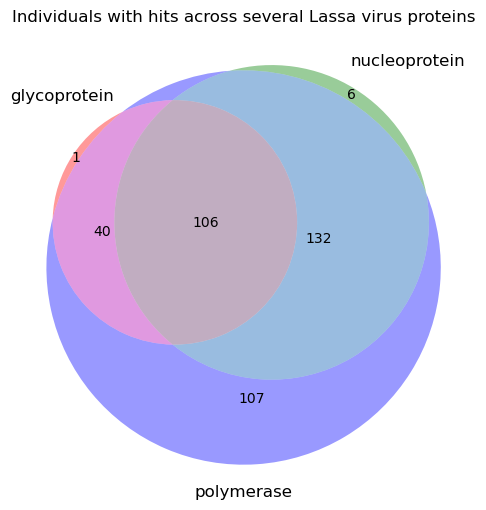

In [59]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn3

set_gp = set(gp_reactive['glycoprotein'].dropna())
set_np = set(np_reactive['nucleoprotein'].dropna())
set_pol = set(pol_reactive['polymerase'].dropna())
set_z = set(z_reactive['z protein'].dropna())

plt.figure(figsize=(6, 8))
venn3([set_gp, set_np, set_pol], set_labels=('glycoprotein', 'nucleoprotein', 'polymerase'))
plt.title("Individuals with hits across several Lassa virus proteins")
plt.show()

In [32]:
set_A

{'glycoprotein', 'nucleoprotein', 'polymerase', 'z protein'}